# Discretization calibration {#sec-calibration}

In this section, we run some error tests to determine which discretization sigma to choose in each environment. These results also give us insights into the effect of discretization on strategy. We run these tests on our three main environments:
* two-armed bandit task;
* risk-reward dilemma;
* stag-hunt game;

First, we import what we need.

In [4]:
# general imports

import numpy as np

import jax.numpy as jnp

import matplotlib.pyplot as plt
import matplotlib as mpl

import pandas as pd
import seaborn as sns

In [5]:
# pyCRLD imports

# Agents
from pyCRLD.Agents.Base import abase
from pyCRLD.Agents.StrategySARSA import stratSARSA
from pyCRLD.Agents.StrategyActorCritic import stratAC

# Environments
from pyDDRL.Environments.SocialDilemma import SocialDilemma
from pyDDRL.Environments.RiskRewardDilemma import RiskRewardDilemma
from pyDDRL.Environments.TwoArmedBandit import TwoArmedBandit

In [6]:
# DDRL imports

from pyDDRL.Agents.DDRLBase import DDRLBase
from pyDDRL.Agents.DDRLSarsa import DDRLSarsa
from pyDDRL.Agents.DDRLActorCritic import DDRLActorCritic

## Errors on a two-armed bandit task

In [18]:
# Poor environment

xs = np.array([[-1, 1],
               [-1, 1]])
ps = np.array([[0.7, 0.3],
               [0.9, 0.1]])
env_poor = TwoArmedBandit(disttype='discrete', xs=xs, ps=ps)

In [19]:
# Rich environment

xs = np.array([[-1, 1],
               [-1, 1]])
ps = np.array([[0.1, 0.9],
               [0.3, 0.7]])
env_rich = TwoArmedBandit(disttype='discrete', xs=xs, ps=ps)

In [20]:
# List of sigmas to compare
sigmas = np.linspace(0.0001, 1., 40)

# Sample strategies
Xs = np.linspace(0.01, 0.99, 11)

In [24]:
# Function to compute mean error
def compute_mean_error(env, Xs, sigmas, path, version):
    errors = np.zeros((len(sigmas), len(Xs)))
    for j, sigma in enumerate(sigmas):
        print("sigma = "+str(sigma))
        mae = stratSARSA(env=env, learning_rates=0.1, 
                         discount_factors=0, choice_intensities=4., use_prefactor=True)
        aei = DDRLSarsa(env, nr_reward_bins=29, discretization_sigma=sigma, 
                        learning_rates=0.1, discount_factors=0, 
                        choice_intensities=4, Rmin=-1, Rmax=1,
                        method="weights", wU=1, use_prefactor=True)
        for k, x in enumerate(Xs):
            X = np.zeros((1, 1, 2))
            X[:, :, 0] = x
            X[:, :, 1] = 1 - x
            distRPE = aei.TDerror(X, norm=True)
            detRPE = mae.TDerror(X, norm=True)
            error = np.linalg.norm(detRPE-distRPE) 
            errors[j, k] = error
    mean_error = np.mean(errors, axis=-1)
    columns = ["X="+str(x) for x in Xs]
    index = ["sigma="+str(sigma) for sigma in sigmas]
    df = pd.DataFrame(errors, index=index, columns=columns)
    df.to_csv(path+"tab_error_df_"+version+".csv")
    return mean_error

In [25]:
path = "../data/error_calculation/"
version_poor = "poor_v1"
version_rich = "rich_v1"

In [26]:
mean_err_poor = compute_mean_error(env_poor, Xs, sigmas, path, version_poor)
mean_err_rich = compute_mean_error(env_rich, Xs, sigmas, path, version_rich)

sigma = 0.0001
sigma = 0.025738461538461536
sigma = 0.05137692307692308
sigma = 0.07701538461538461
sigma = 0.10265384615384615
sigma = 0.12829230769230768
sigma = 0.1539307692307692
sigma = 0.17956923076923076
sigma = 0.20520769230769229
sigma = 0.2308461538461538
sigma = 0.25648461538461537
sigma = 0.2821230769230769
sigma = 0.3077615384615384
sigma = 0.3334
sigma = 0.35903846153846153
sigma = 0.384676923076923
sigma = 0.4103153846153846
sigma = 0.43595384615384614
sigma = 0.46159230769230764
sigma = 0.4872307692307692
sigma = 0.5128692307692307
sigma = 0.5385076923076922
sigma = 0.5641461538461539
sigma = 0.5897846153846154
sigma = 0.6154230769230769
sigma = 0.6410615384615385
sigma = 0.6667
sigma = 0.6923384615384615
sigma = 0.7179769230769231
sigma = 0.7436153846153846
sigma = 0.7692538461538461
sigma = 0.7948923076923077
sigma = 0.8205307692307692
sigma = 0.8461692307692307
sigma = 0.8718076923076923
sigma = 0.8974461538461538
sigma = 0.9230846153846153
sigma = 0.9487230769230769

Text(0, 0.5, 'mean error')

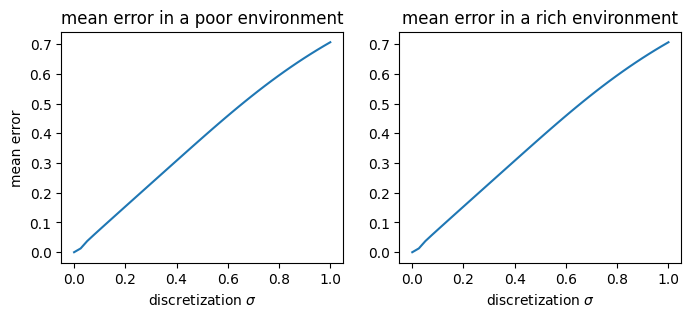

In [27]:
# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3))
ax1.plot(sigmas, mean_err_poor)
ax2.plot(sigmas, mean_err_rich)
ax1.set_xlabel("discretization "+r'$\sigma$')
ax2.set_xlabel("discretization "+r'$\sigma$')
ax1.set_title("mean error in a poor environment")
ax2.set_title("mean error in a rich environment")
ax1.set_ylabel("mean error")

In [28]:
idx = np.argmin(mean_err_poor)
sigmas[idx]

np.float64(0.0001)

## Errors in a risk-reward dilemma

In [7]:
env = RiskRewardDilemma(pc=0.1, pr=0.2, rc=0.5, rr=1, rd=0)

In [8]:
# Discount factors
gammas = [0.4, 0.9]

# List of sigmas to compare
sigmas = np.linspace(0.0001, 1., 40)

# Sample strategies
Xs = np.linspace(0.01, 0.99, 11)

In [9]:
# Function to compute mean error
def compute_mean_error(env, Xs, sigmas, gamma, path, version):
    errors = np.zeros((len(sigmas), len(Xs)))
    for j, sigma in enumerate(sigmas):
        print("sigma = "+str(sigma))
        mae = stratAC(env=env, learning_rates=0.1, 
                      discount_factors=gamma, use_prefactor=True)
        aei = DDRLActorCritic(env, nr_reward_bins=29, discretization_sigma=sigma, 
                              learning_rates=0.1, discount_factors=gamma, 
                              Rmin=0, Rmax=1,
                              method="weights", wU=1, use_prefactor=True)
        for k, x in enumerate(Xs):
            X = np.zeros((1, 2, 2))
            X[:, 0, 0] = x
            X[:, 0, 1] = 1 - x
            X[:, 1, 0] = 1
            distRPE = aei.TDerror(X, norm=True)
            detRPE = mae.TDerror(X, norm=True)
            error = np.linalg.norm(detRPE-distRPE) 
            errors[j, k] = error
    mean_error = np.mean(errors, axis=-1)
    columns = ["X="+str(x) for x in Xs]
    index = ["sigma="+str(sigma) for sigma in sigmas]
    df = pd.DataFrame(errors, index=index, columns=columns)
    df.to_csv(path+"rr_error_df_"+version+".csv")
    return mean_error

In [10]:
path = "../data/error_calculation/"
version_low = "low_v1"
version_high = "high_v1"

In [11]:
mean_err_low = compute_mean_error(env, Xs, sigmas, gammas[0], path, version_low)
mean_err_high = compute_mean_error(env, Xs, sigmas, gammas[1], path, version_high)

sigma = 0.0001
sigma = 0.025738461538461536
sigma = 0.05137692307692308
sigma = 0.07701538461538461
sigma = 0.10265384615384615
sigma = 0.12829230769230768
sigma = 0.1539307692307692
sigma = 0.17956923076923076
sigma = 0.20520769230769229
sigma = 0.2308461538461538
sigma = 0.25648461538461537
sigma = 0.2821230769230769
sigma = 0.3077615384615384
sigma = 0.3334
sigma = 0.35903846153846153
sigma = 0.384676923076923
sigma = 0.4103153846153846
sigma = 0.43595384615384614
sigma = 0.46159230769230764
sigma = 0.4872307692307692
sigma = 0.5128692307692307
sigma = 0.5385076923076922
sigma = 0.5641461538461539
sigma = 0.5897846153846154
sigma = 0.6154230769230769
sigma = 0.6410615384615385
sigma = 0.6667
sigma = 0.6923384615384615
sigma = 0.7179769230769231
sigma = 0.7436153846153846
sigma = 0.7692538461538461
sigma = 0.7948923076923077
sigma = 0.8205307692307692
sigma = 0.8461692307692307
sigma = 0.8718076923076923
sigma = 0.8974461538461538
sigma = 0.9230846153846153
sigma = 0.9487230769230769

Text(0, 0.5, 'mean error')

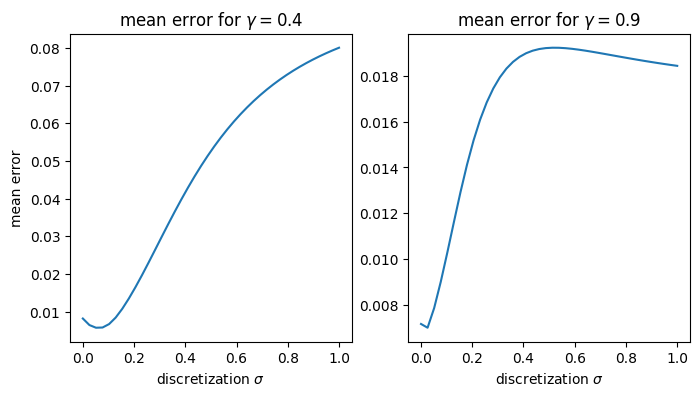

In [12]:
# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3))
ax1.plot(sigmas, mean_err_low)
ax2.plot(sigmas, mean_err_high)
ax1.set_xlabel("discretization "+r'$\sigma$')
ax2.set_xlabel("discretization "+r'$\sigma$')
ax1.set_title("mean error for "+r'$\gamma=0.4$')
ax2.set_title("mean error for "+r'$\gamma=0.9$')
ax1.set_ylabel("mean error")

In [13]:
idx = np.argmin(mean_err_low)
sigmas[idx]

np.float64(0.05137692307692308)

In [14]:
idx = np.argmin(mean_err_high)
sigmas[idx]

np.float64(0.025738461538461536)

## Errors in a stag-hunt game

In [15]:
env = SocialDilemma(R=3, P=0, S=-2, T=1)

In [16]:
# List of sigmas to compare
sigmas = np.linspace(0.0001, 1., 40)

# Sample strategies
Xs = np.linspace(0.01, 0.99, 11)

In [17]:
# Function to compute mean error
def compute_mean_error(env, Xs, sigmas, gamma, path, version):
    errors = np.zeros((len(sigmas), len(Xs)))
    for j, sigma in enumerate(sigmas):
        print("sigma = "+str(sigma))
        mae = stratSARSA(env=env, learning_rates=0.1, choice_intensities=50,
                         discount_factors=gamma, use_prefactor=True)
        aei = DDRLSarsa(env, nr_reward_bins=29, discretization_sigma=sigma, 
                        learning_rates=0.1, discount_factors=gamma, 
                        Rmin=-2, Rmax=3, choice_intensities=50,
                        method="weights", wU=1, use_prefactor=True)
        for k, x in enumerate(Xs):
            X = np.zeros((2, 1, 2))
            X[0, 0, 0] = x
            X[0, 0, 1] = 1 - x
            X[1, 0, 0] = x
            X[1, 0, 1] = 1 - x
            distRPE = aei.TDerror(X, norm=True)
            detRPE = mae.TDerror(X, norm=True)
            error = np.linalg.norm(detRPE-distRPE) 
            errors[j, k] = error
    mean_error = np.mean(errors, axis=-1)
    columns = ["X="+str(x) for x in Xs]
    index = ["sigma="+str(sigma) for sigma in sigmas]
    df = pd.DataFrame(errors, index=index, columns=columns)
    df.to_csv(path+"sh_error_df_"+version+".csv")
    return mean_error

In [18]:
path = "../data/error_calculation/"
version = "v0"

In [19]:
mean_err = compute_mean_error(env, Xs, sigmas, 0.9, path, version)

sigma = 0.0001
sigma = 0.025738461538461536
sigma = 0.05137692307692308
sigma = 0.07701538461538461
sigma = 0.10265384615384615
sigma = 0.12829230769230768
sigma = 0.1539307692307692
sigma = 0.17956923076923076
sigma = 0.20520769230769229
sigma = 0.2308461538461538
sigma = 0.25648461538461537
sigma = 0.2821230769230769
sigma = 0.3077615384615384
sigma = 0.3334
sigma = 0.35903846153846153
sigma = 0.384676923076923
sigma = 0.4103153846153846
sigma = 0.43595384615384614
sigma = 0.46159230769230764
sigma = 0.4872307692307692
sigma = 0.5128692307692307
sigma = 0.5385076923076922
sigma = 0.5641461538461539
sigma = 0.5897846153846154
sigma = 0.6154230769230769
sigma = 0.6410615384615385
sigma = 0.6667
sigma = 0.6923384615384615
sigma = 0.7179769230769231
sigma = 0.7436153846153846
sigma = 0.7692538461538461
sigma = 0.7948923076923077
sigma = 0.8205307692307692
sigma = 0.8461692307692307
sigma = 0.8718076923076923
sigma = 0.8974461538461538
sigma = 0.9230846153846153
sigma = 0.9487230769230769

Text(0, 0.5, 'mean error')

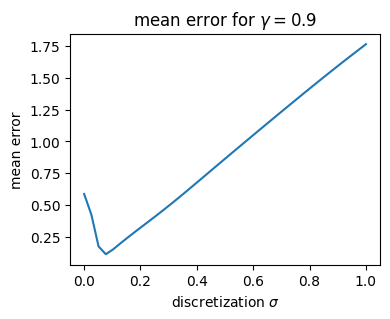

In [20]:
# Plot
fig, ax1 = plt.subplots(1, 1, figsize=(4, 3))
ax1.plot(sigmas, mean_err)
ax1.set_xlabel("discretization "+r'$\sigma$')
ax1.set_title("mean error for "+r'$\gamma=0.9$')
ax1.set_ylabel("mean error")

In [21]:
idx = np.argmin(mean_err)
sigmas[idx]

np.float64(0.07701538461538461)